<a href="https://colab.research.google.com/github/IsaacMandela/Extroverts-vs-Introvert/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#data manipulation libraries
import numpy as np
import random
import os

#data visualization library
import matplotlib.pyplot as plt

#model building libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input,Conv2D, MaxPooling2D, Dense, Flatten, AveragePooling2D, BatchNormalization, Reshape, Layer

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Import my data
# Location of the dataset
data_dir = '/content/drive/MyDrive/archive/Laliga teams'

# Create empty lists
x_train = []
y_train = []

# Load images from each team folder
for team in os.listdir(data_dir):
    team_folder = os.path.join(data_dir, team)

    for image in os.listdir(team_folder):
        image_path = os.path.join(team_folder, image)

        try:
            img = tf.keras.utils.load_img(image_path, target_size=(64, 64))

            img = tf.keras.utils.img_to_array(img)

            x_train.append(img)
            y_train.append(team)

        except:
            continue

# Convert lists into numpy arrays
x_train = np.array(x_train)
y_train = np.array(y_train)


In [ ]:

#checking the shape of the dataset
print('shape of x_train :', x_train.shape)
print('shape of y_train :', y_train.shape)

shape of x_train : (2000, 64, 64, 3)
shape of y_train : (2000,)


In [ ]:
#Normalize the data

The images are ranging from 1 to 255, they should range from 0 to 1

In [ ]:
x_train = x_train/255

In [ ]:
#checking the scale
x_train[1:15]

array([[[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        ...,

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]],


       [[[0., 0., 0.],
         [0., 0., 0.],
         [0., 

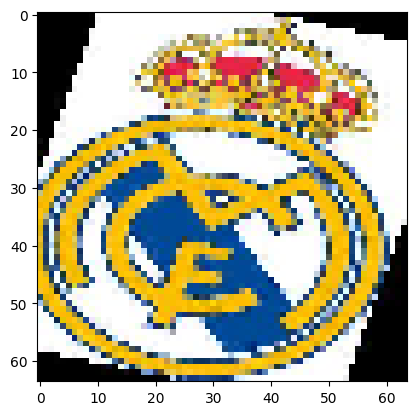

In [31]:
#dispalying any random image
randomimage = random.randint(0, len(x_train))
#plotting the image
plt.imshow(x_train[randomimage, :])
plt.show()

In [ ]:
#Split the data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42
)

Model Building Using Functional API method

In [ ]:
#creating the functional API model
input_layer = Input(shape=(64, 64, 3))
conv_layer1 = Conv2D(32, (3, 3), activation='relu')(input_layer)
pooling_layer1 = MaxPooling2D((2, 2))(conv_layer1)
conv_layer2 = Conv2D(32, (3, 3), activation='relu')(pooling_layer1)
pooling_layer2 = MaxPooling2D((2, 2))(conv_layer2)
flatten_layer = Flatten()(pooling_layer2)
dense_layer1 = Dense(64, activation='relu')(flatten_layer)
#output_layer = Dense(1, activation='sigmoid')(dense_layer1)--binary classification
#Multi-class classification
output_layer = Dense(len(np.unique(y_train)), activation='softmax')(dense_layer1)

model = Model(inputs=input_layer, outputs=output_layer)

In [ ]:
#Encode the y-label from string to integer.
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

In [ ]:
#Compile my model
#We use sparse_categorical_crossentropy since this is a multiclass classification
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='Adam',
    metrics=['accuracy']
)

In [ ]:
#fitting the model
model.fit(x_train, y_train, epochs = 10, batch_size = 32)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 160ms/step - accuracy: 0.5512 - loss: 1.6740
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 121ms/step - accuracy: 0.9837 - loss: 0.0920
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 149ms/step - accuracy: 1.0000 - loss: 0.0039
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 160ms/step - accuracy: 1.0000 - loss: 0.0018
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 138ms/step - accuracy: 1.0000 - loss: 0.0012
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 167ms/step - accuracy: 1.0000 - loss: 9.1104e-04
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - accuracy: 1.0000 - loss: 6.9116e-04
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 1.0000 - loss: 5.4230e-04
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - accuracy: 1.0000 - loss: 4.4394e-04
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - accuracy: 1.0000 - loss: 3.5987e-04


In [ ]:
#testing the model on test set
model.evaluate(x_test,y_test)

In [ ]:
# Select a random image
random_index = random.randint(0, len(x_test) - 1)

# Get the image
random_image = x_test[random_index]

# Get the actual team name
actual_label = encoder.inverse_transform([y_test[random_index]])[0]

In [ ]:
# Make prediction
prediction = model.predict(np.expand_dims(random_image, axis=0))

# Get the predicted team number
predicted_label = np.argmax(prediction)

# Convert number into team name
predicted_team = encoder.inverse_transform([predicted_label])[0]

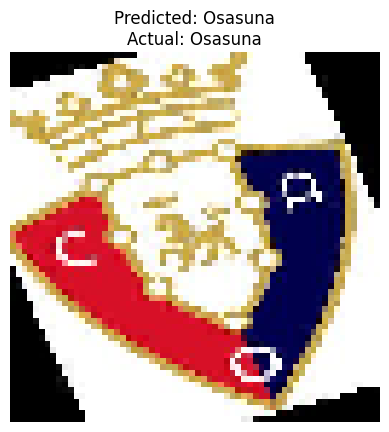

In [19]:
plt.imshow(random_image)
plt.title(f'Predicted: {predicted_team}\nActual: {actual_label}')
plt.axis('off')
plt.show()

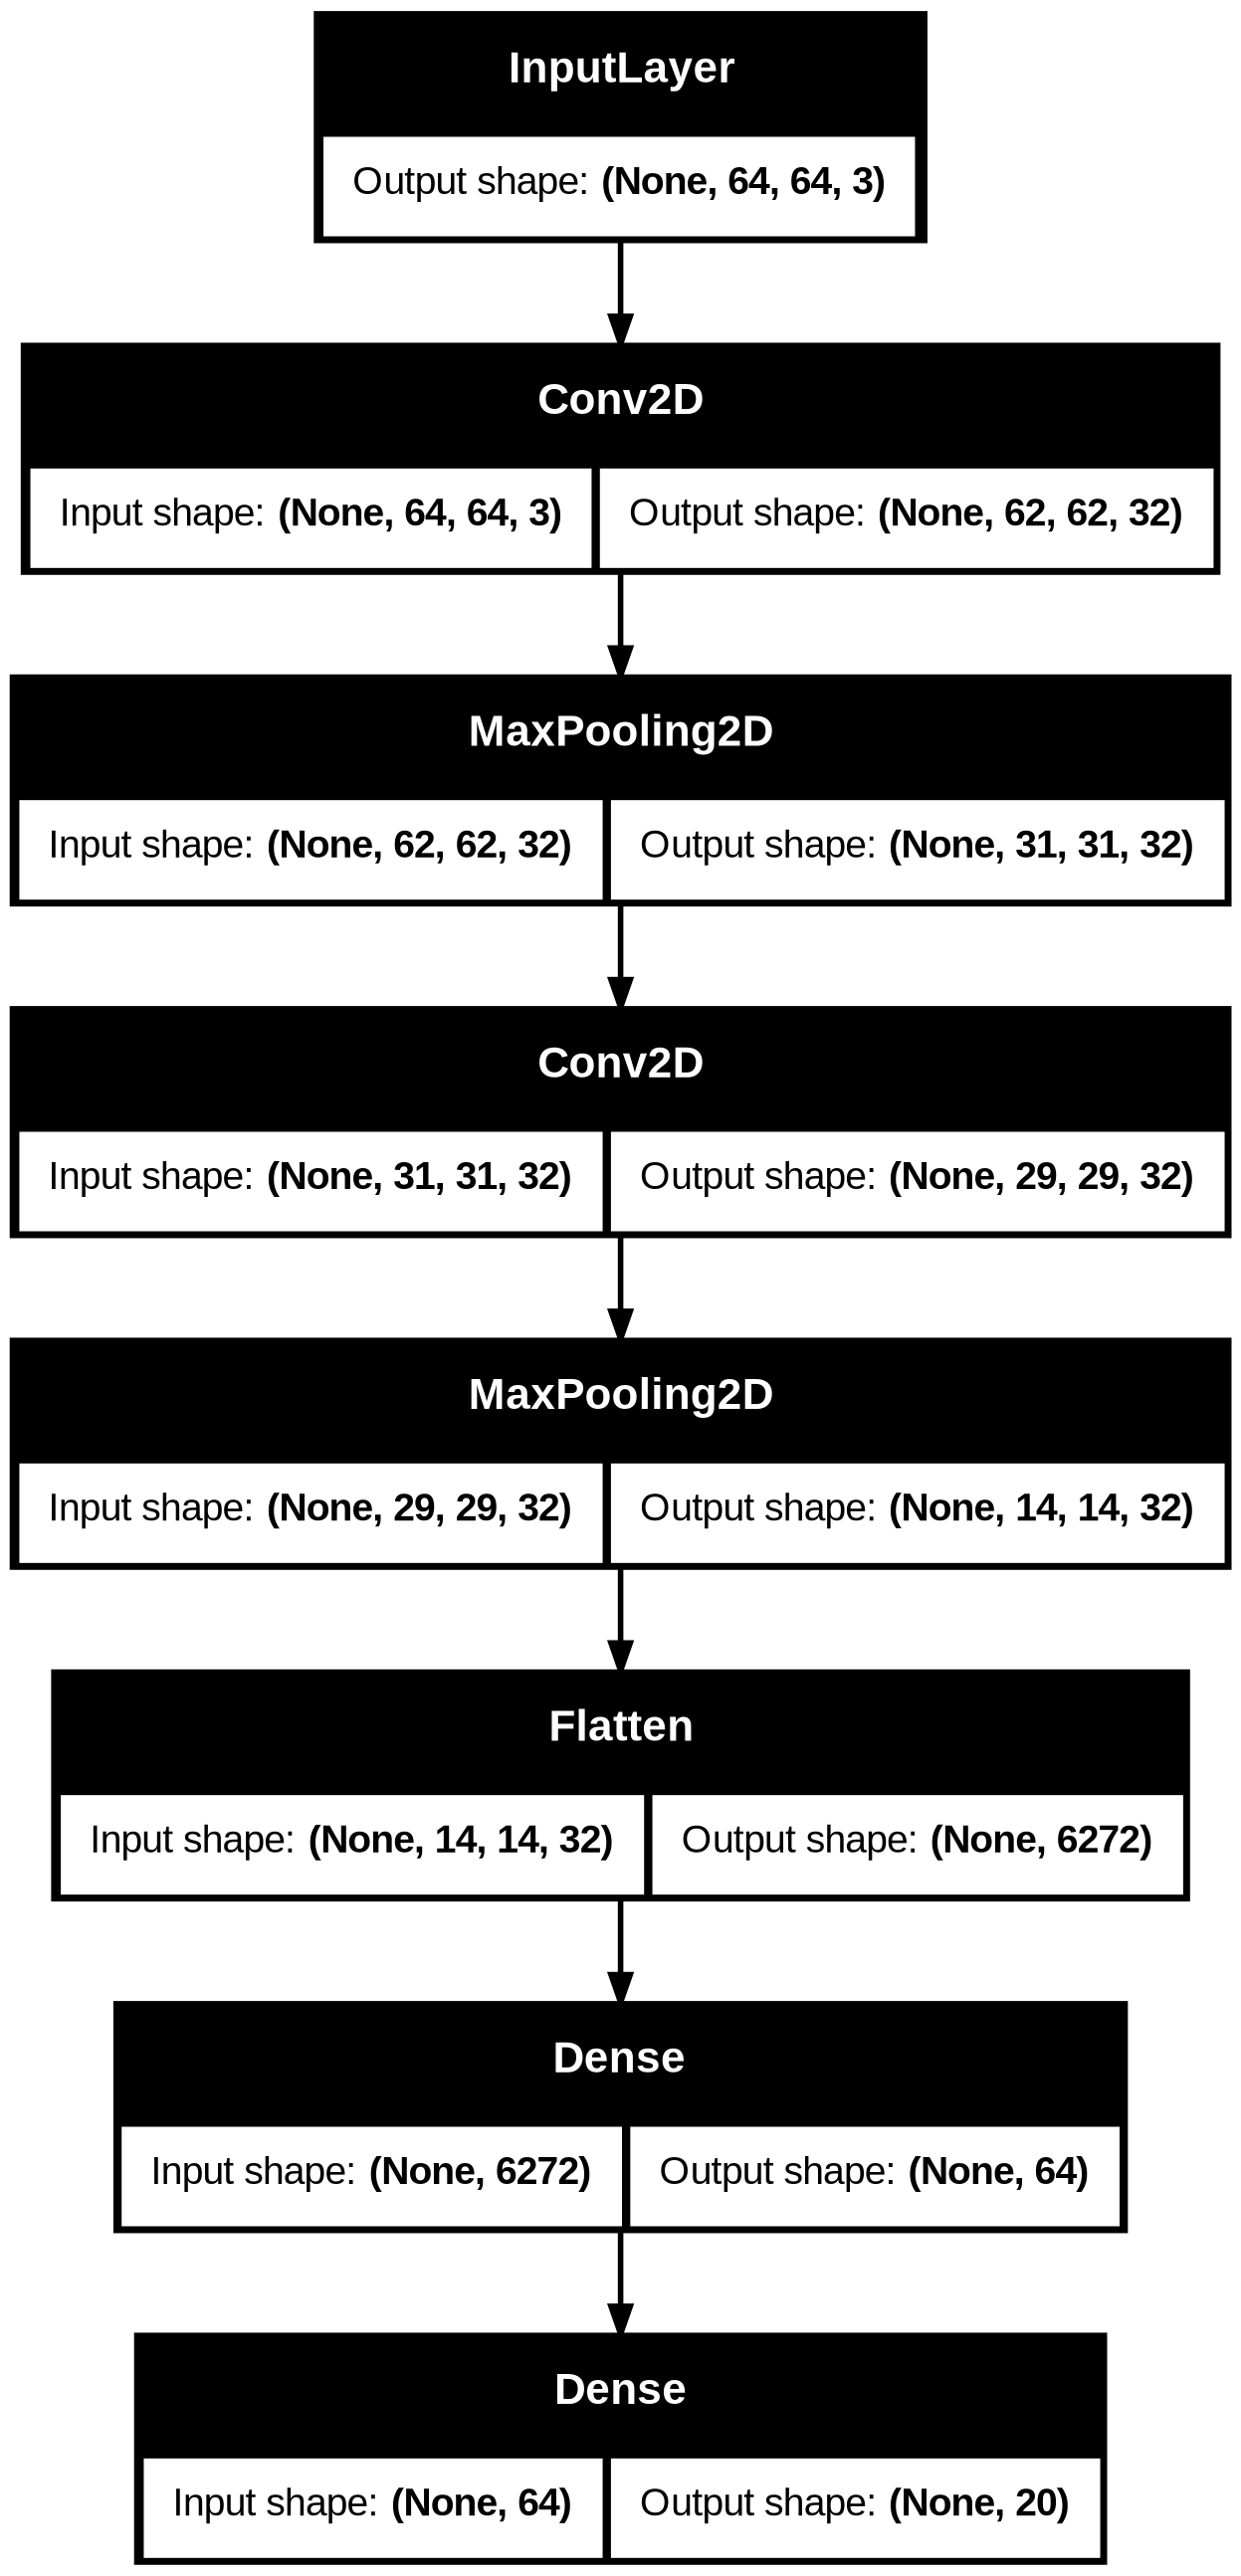

In [20]:
keras.utils.plot_model(model, 'model.png',show_shapes = True)